LN Project - Baseline

Imports

In [1]:
import pandas as pd
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

Data Loading & Cleaning

In [2]:
# 1. Load dataset with proper delimiter and quotation handling
df = pd.read_csv('train.csv', sep=';', on_bad_lines='skip', quotechar='"')

# 2. Strip whitespace from headers and specialty labels
df.columns = df.columns.str.strip()
df['medical_specialty'] = df['medical_specialty'].str.strip()

# 3. Filter out malformed parsing rows (retaining the 12 target specialties)
valid_specialties = df['medical_specialty'].value_counts()
valid_specialties = valid_specialties[valid_specialties > 10].index.tolist()
df = df[df['medical_specialty'].isin(valid_specialties)].copy()

# 4. Fill NaNs to allow safe concatenation across columns
df['description'] = df['description'].fillna("")
df['transcription'] = df['transcription'].fillna("")
df['keywords'] = df['keywords'].fillna("")

print(f"Total valid samples: {len(df)}")
print(f"Target classes count: {df['medical_specialty'].nunique()}")

Total valid samples: 2613
Target classes count: 12


Text Pre-processing and Feature Engineering

In [3]:
# 1. Concatenate all text signals into a single rich text body
df['combined_text'] = (
    df['description'] + " " + 
    df['transcription'] + " " + 
    df['keywords']
)

# 2. Text normalization
def clean_medical_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'[^\w\s]', ' ', text)
    return " ".join(text.split())

df['clean_text'] = df['combined_text'].apply(clean_medical_text)

print("Sample processed text preview:")
print(df['clean_text'].iloc[0][:250] + "...")

Sample processed text preview:
chest pain possible syncopal spells she has been having multiple cardiovascular complaints including chest pains which feel like cramps and sometimes like a dull ache which will last all day long reason for referral chest pain possible syncopal spell...


Train / Validation Split

In [4]:
X_train, X_val, y_train, y_val = train_test_split(
    df['clean_text'],
    df['medical_specialty'],
    test_size=0.20,
    random_state=42,
    stratify=df['medical_specialty']
)

print(f"Training set: {len(X_train)} samples")
print(f"Validation set: {len(X_val)} samples")

Training set: 2090 samples
Validation set: 523 samples


TF-IDF Feature Extraction

In [5]:
tfidf_vectorizer = TfidfVectorizer(
    max_features=25000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_vec = tfidf_vectorizer.fit_transform(X_train)
X_val_vec = tfidf_vectorizer.transform(X_val)

print(f"Extracted TF-IDF feature space size: {X_train_vec.shape[1]}")

Extracted TF-IDF feature space size: 25000


Model Training (Balanced Linear Support Vector Classifier)

In [6]:
# Initialize and train LinearSVC
svm_classifier = LinearSVC(
    C=0.5,
    class_weight='balanced',
    random_state=42
)

svm_classifier.fit(X_train_vec, y_train)
print("Balanced LinearSVC model trained successfully.")

Balanced LinearSVC model trained successfully.


Evaluation

In [7]:
# Predictions
val_predictions = svm_classifier.predict(X_val_vec)

# Metrics
accuracy = accuracy_score(y_val, val_predictions)

print("=" * 60)
print(f"UPGRADED MODEL ACCURACY: {accuracy * 100:.2f}%")
print("=" * 60)
print("\nClassification Report (Precision, Recall, F1-Score):")
print(classification_report(y_val, val_predictions))

UPGRADED MODEL ACCURACY: 49.52%

Classification Report (Precision, Recall, F1-Score):
                          precision    recall  f1-score   support

Cardiovascular-Pulmonary       0.52      0.62      0.56        60
             Dermatology       0.80      0.80      0.80         5
        Gastroenterology       0.52      0.76      0.62        38
        General Medicine       0.65      0.90      0.76        41
               Neurology       0.30      0.31      0.30        36
            Neurosurgery       0.18      0.25      0.21        16
   Obstetrics-Gynecology       0.49      0.78      0.60        27
           Ophthalmology       0.52      0.93      0.67        14
              Orthopedic       0.38      0.41      0.39        59
   Psychiatry-Psychology       0.64      0.88      0.74         8
               Radiology       0.29      0.25      0.27        44
                 Surgery       0.64      0.35      0.45       175

                accuracy                           0.5

Output Analysis

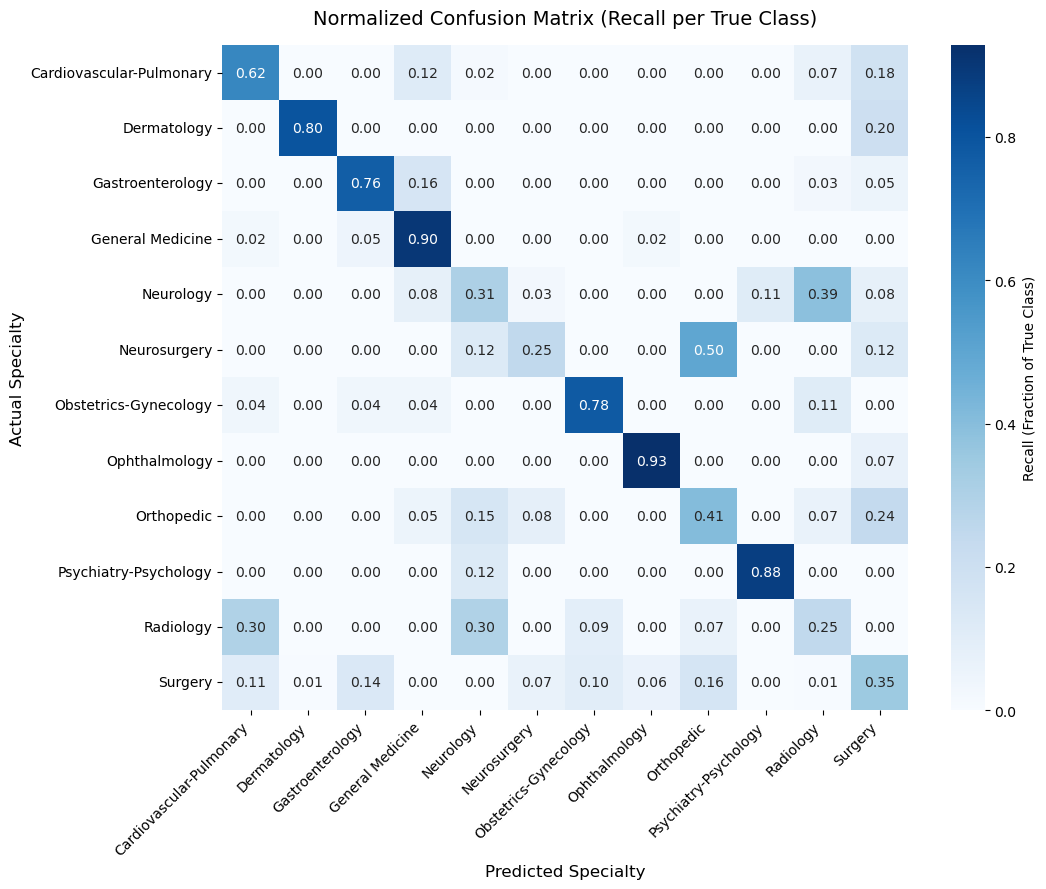

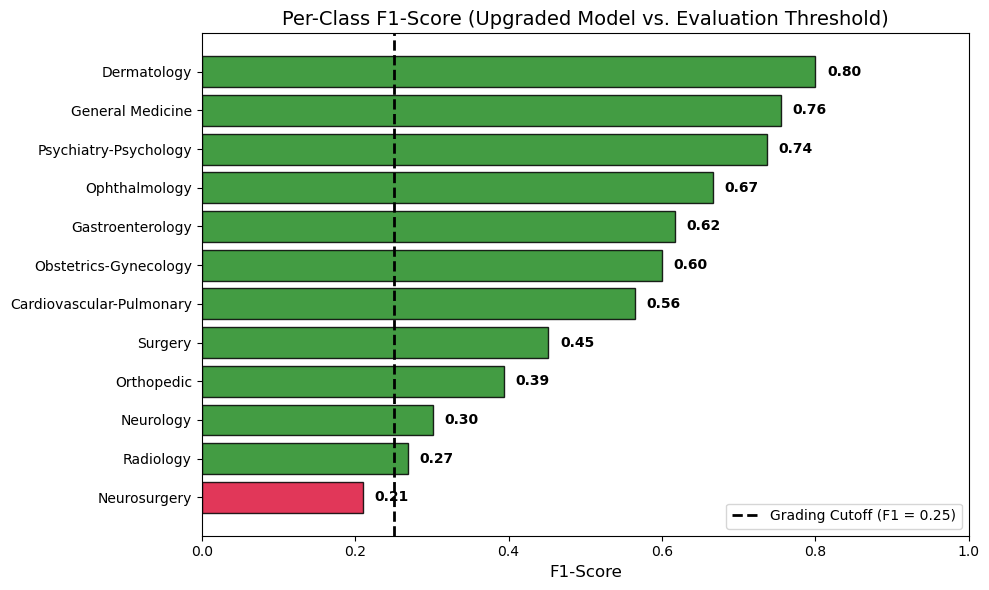

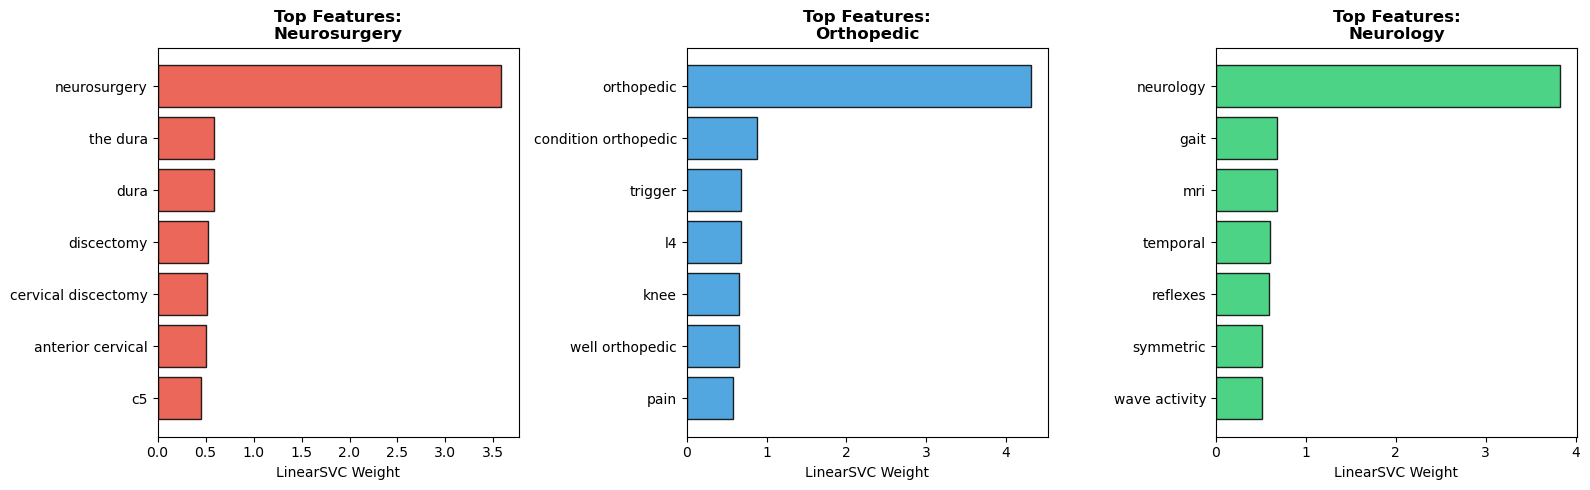

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

labels = sorted(df['medical_specialty'].unique())

# ==========================================
# Plot 1: Normalized Confusion Matrix Heatmap
# ==========================================
cm_norm = confusion_matrix(y_val, val_predictions, labels=labels, normalize='true')

plt.figure(figsize=(11, 9))
sns.heatmap(
    cm_norm, 
    annot=True, 
    fmt='.2f', 
    cmap='Blues', 
    xticklabels=labels, 
    yticklabels=labels,
    cbar_kws={'label': 'Recall (Fraction of True Class)'}
)
plt.title('Normalized Confusion Matrix (Recall per True Class)', fontsize=14, pad=15)
plt.xlabel('Predicted Specialty', fontsize=12)
plt.ylabel('Actual Specialty', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ==========================================
# Plot 2: Per-Class F1 vs. 25% Threshold Bar
# ==========================================
report_dict = classification_report(y_val, val_predictions, output_dict=True)
f1_data = pd.DataFrame({
    'Specialty': labels,
    'F1_Score': [report_dict[cls]['f1-score'] for cls in labels]
}).sort_values(by='F1_Score', ascending=True)

plt.figure(figsize=(10, 6))
bar_colors = ['crimson' if score < 0.25 else 'forestgreen' for score in f1_data['F1_Score']]
bars = plt.barh(f1_data['Specialty'], f1_data['F1_Score'], color=bar_colors, edgecolor='black', alpha=0.85)

# The critical 0.25 line from the grading criteria
plt.axvline(x=0.25, color='black', linestyle='--', linewidth=2, label='Grading Cutoff (F1 = 0.25)')
plt.title('Per-Class F1-Score (Upgraded Model vs. Evaluation Threshold)', fontsize=14)
plt.xlabel('F1-Score', fontsize=12)
plt.xlim(0, 1.0)

for bar, score in zip(bars, f1_data['F1_Score']):
    plt.text(bar.get_width() + 0.015, bar.get_y() + bar.get_height()/2, f"{score:.2f}", va='center', fontsize=10, fontweight='bold')

plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

# ==========================================
# Plot 3: Top Discriminative Features per Class
# ==========================================
feature_names = np.array(tfidf_vectorizer.get_feature_names_out())
svm_coefficients = svm_classifier.coef_
class_index = {cls: idx for idx, cls in enumerate(svm_classifier.classes_)}

confused_classes = ['Neurosurgery', 'Orthopedic', 'Neurology']
colors = ['#e74c3c', '#3498db', '#2ecc71']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
top_k = 7

for ax, cls_name, col in zip(axes, confused_classes, colors):
    idx = class_index[cls_name]
    top_indices = np.argsort(svm_coefficients[idx])[-top_k:]
    words = feature_names[top_indices]
    weights = svm_coefficients[idx][top_indices]
    
    ax.barh(words, weights, color=col, edgecolor='black', alpha=0.85)
    ax.set_title(f'Top Features:\n{cls_name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('LinearSVC Weight', fontsize=10)

plt.tight_layout()
plt.show()